# 05. Ranking: датасет кандидатов и CatBoost

Стадия: ranking. Retrieval — iALS со 128 факторами (E05). Ranking-модель получает для каждого пользователя 100 кандидатов от retrieval и переупорядочивает их по признакам.

Шаг 1: датасет «пользователь, кандидат, метка» без утечки, проверка, что утечки нет, и опорная линия ranking — порядок самого retrieval. Шаг 2: CatBoost на признаках кандидата и пары «пользователь — кандидат». Код: `packages/training/src/training/ranking/`; данные: `data/processed/ranking_v2/` (собрать: `uv run python -m training.ranking.dataset`).

## Как строится датасет

Метка 1 — кандидат, который пользователь досмотрел, но мы его спрятали. Чтобы retrieval не «знал» спрятанное (утечка), train-пользователей делим на 5 частей, и для каждой части iALS обучается на остальных четырёх. Для своей части эти люди новые, как val-пользователи для итоговой модели:

- `input` — всё, кроме спрятанного: исключается из кандидатов, его `completed` дают вектор пользователя;
- `target` — 20% его `completed` (не меньше одного): это метки 1. Прячем только аниме, продолжение которого человек **не** досмотрел. Иначе внутри франшизы появляется «дыра»: в истории 1-й и 3-й сезон, а спрятан 2-й. Такую дыру легко угадать по связям франшизы, а в продукте её почти не бывает — сезоны смотрят по порядку, и задача ленты — угадать, что посмотреть **дальше**. То же правило действует для val/test (`training.interactions.split.pick_targets`).

Для val кандидаты дают iALS, обученный на всех train-пользователях: это ровно та ситуация, в которой ranking будет работать.

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training.evaluation import metrics, protocol, stats
from training.interactions import store
from training.ranking import dataset as rd

candidates = pd.read_csv(rd.OUTPUT / "candidates.csv")
targets = pd.read_csv(rd.OUTPUT / "targets.csv")
candidates.head()

,group,fold,user_id,anime_id,retrieval_score,retrieval_rank,label
0,train,0,5850,10793,1.024803,1,0
1,train,0,5850,22199,0.949151,2,1
2,train,0,5850,11111,0.907812,3,0
3,train,0,5850,28677,0.905284,4,0
4,train,0,5850,40852,0.899968,5,1


In [13]:
summary = candidates.groupby("group").agg(
    rows=("label", "size"),
    users=("user_id", "nunique"),
    positive_share=("label", "mean"),
)
summary.round(4)

,rows,users,positive_share
group,,,
train,138600,1386,0.1902
val,17300,173,0.1795


## Проверка, что утечки нет

`recall@100` по частям: какая доля спрятанных ответов попала в 100 кандидатов. Если бы iALS видел спрятанное у train-пользователей, у их частей значение было бы заметно выше, чем у val (в отдельной проверке SVD, видевший пользователей, давал 0,589 против честных 0,497). Здесь они должны быть близки.

In [14]:
rd.recall_of_candidates(candidates, targets).round(4)

group  fold
train   0      0.5551
        1      0.5735
        2      0.5852
        3      0.5664
        4      0.5729
val    -1      0.5816
Name: recall, dtype: float64

## Насколько полезен балл retrieval

Доля позитивов по позициям в списке кандидатов (корзины по 10 позиций). Если retrieval хороший, доля падает от первых позиций к последним. Ranking имеет смысл, если внутри этого порядка ещё есть что улучшать.

group,train,val
rank_bucket,,
1,0.432,0.430
11,0.290,0.284
21,0.232,0.234
31,0.188,0.178
41,0.168,0.150
51,0.142,0.129
61,0.130,0.111
71,0.115,0.104
81,0.108,0.093


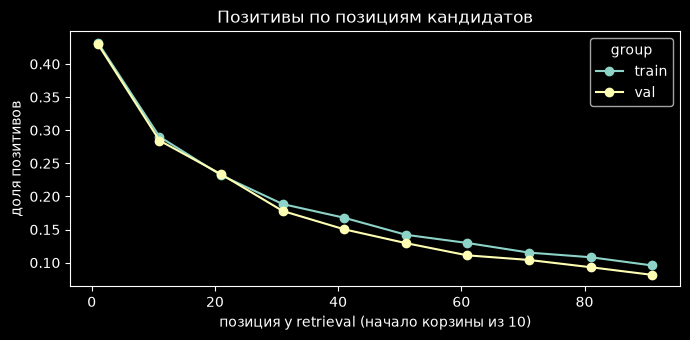

In [15]:
candidates["rank_bucket"] = (candidates["retrieval_rank"] - 1) // 10 * 10 + 1
by_rank = candidates.groupby(["group", "rank_bucket"])["label"].mean().unstack(0)

ax = by_rank.plot(marker="o", figsize=(7, 3.5))
ax.set_xlabel("позиция у retrieval (начало корзины из 10)")
ax.set_ylabel("доля позитивов")
ax.set_title("Позитивы по позициям кандидатов")
plt.tight_layout()
by_rank.round(3)

Ранжированию есть что делать. Даже на местах 51–100 попадается 8–14% правильных ответов. Если CatBoost по другим признакам (франшиза, жанры, популярность) поймёт, какие из них подходят, он поднимет их в топ-10.

## Опорная линия для ranking

Ranking будет переупорядочивать 100 кандидатов. Самое простое — оставить порядок retrieval. Посчитаем на val те же метрики итогового списка, что и раньше (`ndcg@10`, `hit_rate@10`, `recall@10`); спрятанные ответы считаем полностью, включая не попавшие в кандидаты, поэтому числа сравнимы с прошлыми ноутбуками. Любая ranking-модель должна обогнать эту строку.

In [16]:
table, catalog = store.load_interactions()
cases = protocol.build_cases(table, "val")


def list_metrics(scored: pd.DataFrame, score_column: str, ks=(10, 20)) -> pd.DataFrame:
    """Метрики по каждому val-пользователю для порядка кандидатов по score_column (по убыванию)."""
    rows = {}
    for user_id, group in scored.groupby("user_id"):
        ranked = group.sort_values(score_column, ascending=False)["anime_id"].to_numpy()
        targets_u = cases[user_id][1]
        row = {}
        for k in ks:
            row[f"recall@{k}"] = metrics.recall_at_k(ranked, targets_u, k)
            row[f"hit_rate@{k}"] = metrics.hit_rate_at_k(ranked, targets_u, k)
            row[f"ndcg@{k}"] = metrics.ndcg_at_k(ranked, targets_u, k)
        rows[user_id] = row
    return pd.DataFrame.from_dict(rows, orient="index")


val = candidates[candidates["group"] == "val"]
baseline = list_metrics(val, "retrieval_score")
baseline_summary = pd.DataFrame({
    m: {"среднее": baseline[m].mean(), **dict(zip(["нижняя", "верхняя"], stats.bootstrap_ci(baseline[m].to_numpy())))}
    for m in ["ndcg@10", "hit_rate@10", "recall@10"]
}).T
baseline_summary.round(4)

,среднее,нижняя,верхняя
ndcg@10,0.4841,0.4434,0.5266
hit_rate@10,0.9133,0.8728,0.9538
recall@10,0.1946,0.1674,0.2231


Вывод по шагу 1:

- Датасет: 1386 train-пользователей (по 100 кандидатов, всего 138 600 строк) и 173 val-пользователя (17 300 строк); позитивов около 19% у train и 18% у val.
- Утечки нет: `recall@100` у пяти train-частей 0,555–0,585, у val 0,582 — внутри того же диапазона. Если бы iALS видел спрятанное, у train было бы заметно выше.
- Значение `recall@100` у val совпадает с результатом E05 (0,582), то есть кандидаты построены той же моделью, что и в сравнении retrieval.
- Опорная линия ranking — порядок retrieval: `ndcg@10` 0,484 [0,443; 0,527]. Следующий шаг — признаки для каждой пары «пользователь, кандидат» и первая ranking-модель.

## Шаг 2: CatBoost на признаках кандидата и пары «пользователь — кандидат»

Модель — `CatBoostRanker` с функцией потерь `YetiRank`: она учит порядок внутри списка 100 кандидатов каждого пользователя с упором на верх списка. Код модели: `packages/training/src/training/ranking/model.py`. Признаки считаются в `packages/core/src/core/catalog/` (`anime.py`, `franchise.py`, `history.py`, сборка — `pairs.py`): этот код общий для обучения и будущей выдачи, чтобы признаки считались одинаково.

Группы признаков (25 штук, описание каждого — после ячейки с `rk.prepare()`):
- от iALS: балл и место кандидата;
- популярность: `log(1 + число train-зрителей)`, для train-частей — без пользователей своей части (иначе утечка);
- аниме: год, серии, длительность, тип, возрастной рейтинг, первоисточник, студия;
- франшиза: связан ли кандидат с досмотренным (продолжение, прямая связь, общая хронология);
- жанры: насколько жанры кандидата типичны для истории пользователя;
- профиль: размер истории, привычный год и тип аниме;
- избранное: те же связи и жанры, но только по избранному.

Всё, что зависит от пользователя, считается только по его input-истории. Текущие `score`, `status`, `episodes_aired` аниме не используем: это сегодняшнее состояние сайта, утечка из будущего. `rk.prepare()` возвращает все 25 признаков, и `make_pool` не даст обучить модель на неполном наборе без явного `partial=True` (так делает только сравнение групп ниже).

In [17]:
from core.catalog import anime
from training.ranking import model as rk

data, columns = rk.prepare()
data[columns].head()

,retrieval_score,retrieval_rank,popularity,year,episodes,duration,total_minutes,kind,rating,origin,...,genre_max,history_size,mean_year,year_gap,kind_share,fav_prequel_completed,fav_n_related,fav_n_franchise,fav_genre_match,fav_genre_max
0,1.024803,1,5.117994,2011.0,22.0,24.0,528.0,tv,r,original,...,0.191860,172,2015.703488,-4.703488,0.930233,0,0,0,NaN,NaN
1,0.949151,2,6.075346,2014.0,24.0,23.0,552.0,tv,r,manga,...,0.627907,172,2015.703488,-1.703488,0.930233,0,0,0,NaN,NaN
2,0.907812,3,5.693732,2012.0,12.0,24.0,288.0,tv,r,novel,...,0.348837,172,2015.703488,-3.703488,0.930233,0,0,0,NaN,NaN
3,0.905284,4,5.141664,2015.0,12.0,24.0,288.0,tv,pg_13,manga,...,0.441860,172,2015.703488,-0.703488,0.930233,0,0,0,NaN,NaN
4,0.899968,5,5.802118,2021.0,11.0,24.0,264.0,tv,pg_13,manga,...,0.441860,172,2015.703488,5.296512,0.930233,0,0,0,NaN,NaN


Признаки (25). Всё, что зависит от пользователя, считается только по его input-истории: спрятанные 20% признаки не видят.

* `retrieval_score` — балл iALS: скалярное произведение вектора пользователя и вектора аниме
* `retrieval_rank` — место кандидата в списке iALS (1 — лучший)
* `popularity` — log(1 + число train-зрителей аниме); для train-пользователя считается без его части
* `year` — год выхода аниме
* `episodes` — число серий (0 в данных = неизвестно, NaN)
* `duration` — длительность серии в минутах (0 = неизвестно, NaN)
* `total_minutes` — серии × длительность: сколько минут займёт просмотр целиком
* `kind` — тип: tv, movie, ova, ona, special, tv_special
* `rating` — возрастной рейтинг: g, pg, pg_13, r, r_plus
* `origin` — первоисточник: manga, original, light_novel, …
* `studio` — первая студия аниме (id)
* `prequel_completed` — сколько досмотренных аниме имеют кандидата своим продолжением (досмотрена «Магическая битва» → у «Магической битвы 2» значение 1)
* `n_related` — сколько досмотренных аниме напрямую связаны с кандидатом любой связью: сиквел, приквел, спин-офф, побочная история, альтернативная версия
* `n_franchise` — сколько досмотренных аниме стоят с кандидатом в одной хронологии франшизы (связь может быть через несколько шагов)
* `genre_match` — средняя по жанрам кандидата доля истории с этим жанром: 0,38 значит, что в среднем жанр кандидата есть у 38% досмотренного
* `genre_max` — наибольшая такая доля: есть ли у кандидата хоть один «любимый» жанр пользователя
* `history_size` — сколько аниме в input-истории пользователя (одинаково для всех его кандидатов)
* `mean_year` — средний год выхода досмотренного: любит старое или новое (одинаково для всех его кандидатов)
* `year_gap` — `year` − `mean_year`: насколько кандидат новее (+) или старше (−) привычного
* `kind_share` — доля истории того же типа, что кандидат: у пользователя 91% tv, кандидат tv → 0,91
* `fav_prequel_completed` — как `prequel_completed`, но считаются только избранные аниме из input
* `fav_n_related` — как `n_related`, только по избранному
* `fav_n_franchise` — как `n_franchise`, только по избранному
* `fav_genre_match` — как `genre_match`, но доли жанров среди избранного (нет избранного — NaN: вкус неизвестен)
* `fav_genre_max` — как `genre_max`, только по избранному (нет избранного — NaN: вкус неизвестен)


### Связь признаков между собой и с меткой

Ранговая корреляция (Спирмена) числовых признаков на train-кандидатах. Строка `label` показывает, насколько признак сам по себе связан с тем, что кандидат оказался спрятанным ответом. Это связь по всем строкам сразу, без учёта, что сравнивать надо внутри списка одного пользователя, поэтому это ориентир, а не оценка полезности признака.

retrieval_rank          -0.228041
genre_max               -0.047467
total_minutes           -0.027128
popularity              -0.022584
fav_genre_max           -0.021665
episodes                -0.021245
kind_share              -0.017494
mean_year               -0.006170
year_gap                -0.005338
duration                -0.004585
year                     0.001443
genre_match              0.027742
fav_genre_match          0.044705
fav_prequel_completed    0.049636
fav_n_related            0.062454
fav_n_franchise          0.080267
n_franchise              0.244523
prequel_completed        0.283260
n_related                0.283720
history_size             0.359320
retrieval_score          0.431153
Name: label, dtype: float64

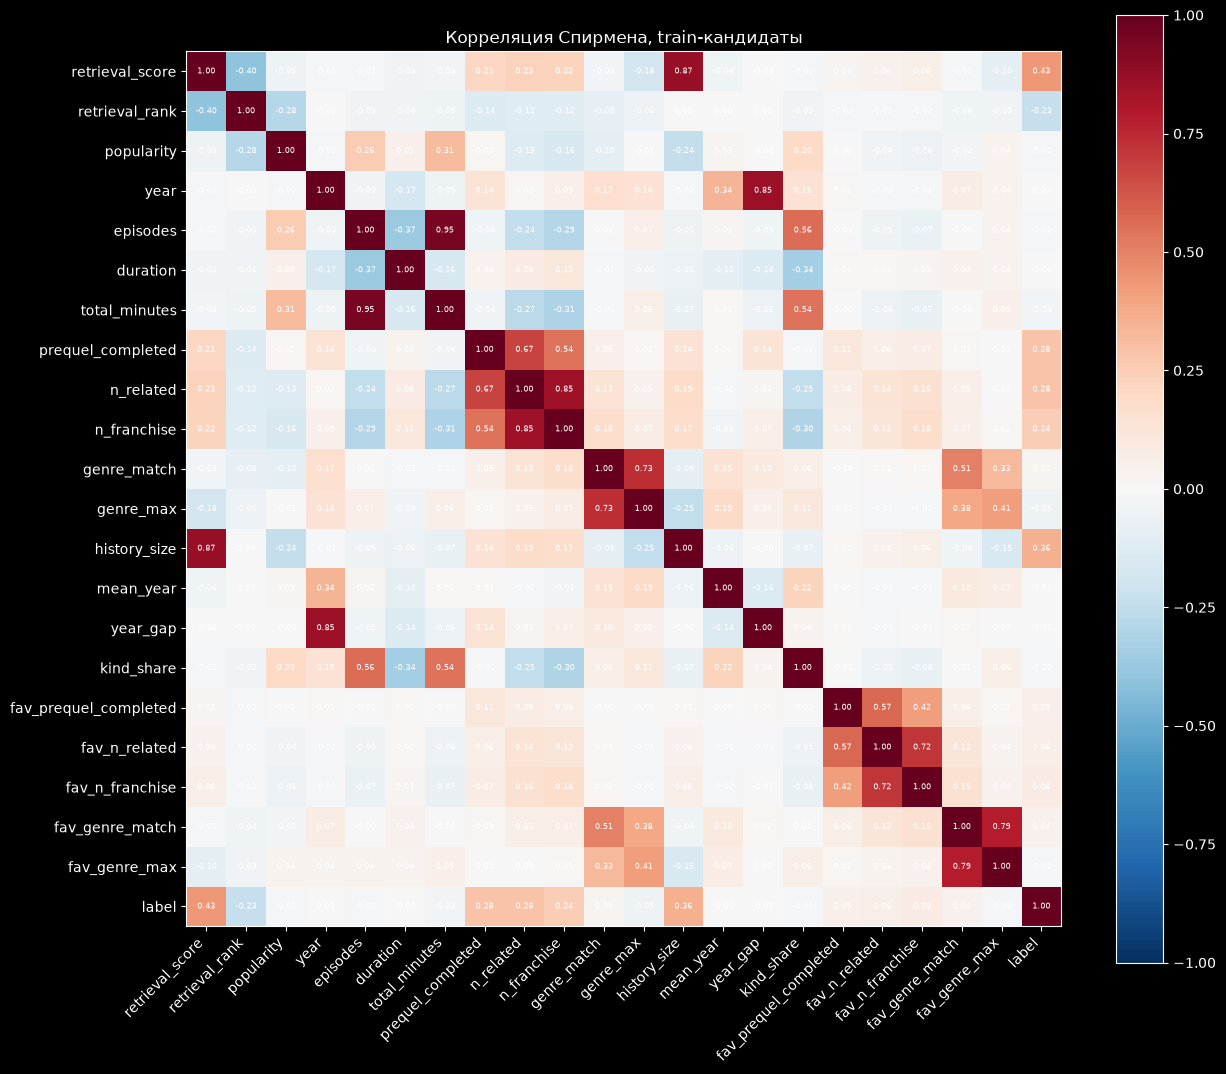

In [18]:
numeric = [c for c in columns if c not in anime.CATEGORICAL_FEATURES] + ["label"]
corr = data.loc[data["group"] == "train", numeric].corr(method="spearman")

fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric)), numeric, rotation=45, ha="right")
ax.set_yticks(range(len(numeric)), numeric)
for i in range(len(numeric)):
    for j in range(len(numeric)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im)
ax.set_title("Корреляция Спирмена, train-кандидаты")
plt.tight_layout()
corr["label"].drop("label").sort_values()

Доля позитивов по типу аниме и первоисточнику (категориальные признаки в корреляцию не входят).

In [19]:
train_rows = data[data["group"] == "train"]
pd.concat({c: train_rows.groupby(c)["label"].agg(доля_позитивов="mean", строк="size") for c in ["kind", "origin"]}).round(3)

доля_позитивов   строк
kind   movie                     0.201   20942
       ona                       0.147    4678
       ova                       0.220    6598
       special                   0.228    3752
       tv                        0.187  100529
       tv_special                0.171    2101
origin book                      0.276     656
       card_game                 0.098      41
       four_koma_manga           0.189    1669
       game                      0.205    1182
       light_novel               0.216   33215
       manga                     0.178   68225
       mixed_media               0.181     166
       music                     0.188      32
       novel                     0.188    2935
       original                  0.195   16777
       other                     0.181     299
       picture_book              0.500       2
       visual_novel              0.204    3162
       web_manga                 0.173    9212
       web_novel                 0.118    1027

### CatBoost с параметрами по умолчанию

Обучаем на всех train-кандидатах (500 итераций, темп 0,05, глубина 6), сравниваем на val с опорной линией — порядком iALS: средние, 95% интервалы и парная разница (`diff`).

In [20]:
train_pool = rk.make_pool(data[data["group"] == "train"], columns)
default_model = rk.train_ranker(train_pool)
default_report = rk.report(rk.evaluate_on_val(default_model, data, columns))
default_report.round(4)

,baseline,baseline_low,baseline_high,catboost,catboost_low,catboost_high,diff,diff_low,diff_high
ndcg@10,0.4841,0.4434,0.5266,0.5898,0.5458,0.6356,0.1057,0.0820,0.1294
hit_rate@10,0.9133,0.8728,0.9538,0.9249,0.8844,0.9595,0.0116,-0.0173,0.0405
recall@10,0.1946,0.1674,0.2231,0.2347,0.2037,0.2667,0.0401,0.0247,0.0554


In [21]:
pd.Series(default_model.get_feature_importance(data=train_pool), index=columns).sort_values(ascending=False).round(3)

prequel_completed        0.048
retrieval_rank           0.043
n_related                0.025
n_franchise              0.018
popularity               0.013
studio                   0.009
kind_share               0.008
year                     0.006
retrieval_score          0.006
genre_match              0.005
total_minutes            0.005
origin                   0.004
mean_year                0.004
year_gap                 0.003
history_size             0.003
duration                 0.003
genre_max                0.003
episodes                 0.002
rating                   0.001
kind                     0.001
fav_n_franchise          0.001
fav_genre_match          0.001
fav_prequel_completed    0.000
fav_genre_max            0.000
fav_n_related            0.000
dtype: float64

### Подбор параметров через Optuna

Перебираем темп обучения, глубину деревьев и регуляризацию листьев. Обучаемся на частях train 1–4 и сравниваем наборы по NDCG@10 на части 0 с ранней остановкой; **val в подборе не участвует**, иначе итоговая цифра на val была бы подогнанной. Число итераций итоговой модели — лучшая итерация из ранней остановки.

Одна попытка — около 1,5 минуты; 15 попыток — около 25 минут.

In [22]:
N_TRIALS = 15
study = rk.tune_ranker(data, columns, n_trials=N_TRIALS, timeout=1800)
trials = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs")).sort_values("value", ascending=False)
trials.head(10).round(4)

,number,value,params_depth,params_l2_leaf_reg,params_learning_rate,user_attrs_best_iteration
12,12,0.6571,7,2.6984,0.2147,311
13,13,0.6566,6,5.3293,0.2531,415
9,9,0.6521,6,1.1712,0.0805,419
14,14,0.6505,7,4.1263,0.1331,273
10,10,0.6497,7,1.9262,0.1782,161
8,8,0.6490,7,1.9722,0.0688,290
1,1,0.6460,4,1.6999,0.1012,427
4,4,0.6457,5,1.8560,0.1906,206
11,11,0.6443,8,1.3391,0.2068,83
0,0,0.6392,8,12.0571,0.0551,590


In [23]:
best_params = dict(study.best_params)
best_params["iterations"] = int(study.best_trial.user_attrs["best_iteration"]) + 1
tuned_model = rk.train_ranker(train_pool, best_params)
tuned_report = rk.report(rk.evaluate_on_val(tuned_model, data, columns))
print("лучшие параметры:", {k: round(v, 4) if isinstance(v, float) else v for k, v in best_params.items()})
tuned_report.round(4)

лучшие параметры: {'learning_rate': 0.2147, 'depth': 7, 'l2_leaf_reg': 2.6984, 'iterations': 312}


,baseline,baseline_low,baseline_high,catboost,catboost_low,catboost_high,diff,diff_low,diff_high
ndcg@10,0.4841,0.4434,0.5266,0.5870,0.5441,0.6340,0.1029,0.0798,0.1277
hit_rate@10,0.9133,0.8728,0.9538,0.9249,0.8844,0.9595,0.0116,-0.0173,0.0405
recall@10,0.1946,0.1674,0.2231,0.2318,0.2006,0.2638,0.0372,0.0222,0.0528


### Вклад групп признаков

Обучаем модель на всех группах и по модели без каждой группы признаков пары; отдельно — модель только на признаках iALS, популярности и аниме (так выглядел шаг 2 до признаков пары). `diff` — парная разница с моделью на всех группах, `vs_ials` — с порядком iALS. Если без группы метрика не падает (интервал `diff` содержит 0), группа не нужна. 6 обучений, около 10 минут.

In [24]:
ablation = rk.ablation(data)
ablation.round(4)

,ndcg@10,diff,diff_low,diff_high,vs_ials,vs_ials_low,vs_ials_high
все группы,0.5898,0.0000,0.0000,0.0000,0.1057,0.0820,0.1294
без franchise,0.5173,-0.0725,-0.0954,-0.0510,0.0332,0.0181,0.0486
без genres,0.5915,0.0017,-0.0052,0.0090,0.1074,0.0839,0.1324
без profile,0.5890,-0.0008,-0.0096,0.0082,0.1049,0.0821,0.1297
без favourites,0.5902,0.0004,-0.0066,0.0073,0.1061,0.0828,0.1311
шаг 2 (без признаков пары),0.5080,-0.0818,-0.1046,-0.0591,0.0239,0.0105,0.0378


### Проверка на утечку

Если бы признак «видел» спрятанное у train-пользователей, на train он угадывал бы заметно чаще, чем на val. Ниже — доля правильных ответов среди кандидатов с признаком > 0.

In [25]:
leak_check = {c: data[data[c] > 0].groupby("group")["label"].mean() for c in ["prequel_completed", "n_franchise", "fav_n_franchise"]}
pd.DataFrame(leak_check).round(3)

,prequel_completed,n_franchise,fav_n_franchise
group,,,
train,0.510,0.346,0.521
val,0.477,0.314,0.468


Проверка правила протокола: ни один спрятанный ответ не должен быть «дырой» — приквелом аниме, которое пользователь уже досмотрел в input. Доля таких среди правильных ответов должна быть 0 и у train, и у val.

In [26]:
from core.catalog import franchise

# input-истории всех пользователей датасета и связи «сиквел»
item_ids = np.sort(catalog)
is_train_completed = (table["split"] == "train") & (table["status"] == "completed")
users = rd.split_train_users(table, item_ids, np.sort(table.loc[is_train_completed, "user_id"].unique()))
histories = rd.input_histories(table, item_ids, users)
links = franchise.load_anime_links()
prequels = links[links["link"] == "sequel"].rename(columns={"source": "anime_id", "anime_id": "sequel_id"})

# «дыра»: кандидат — приквел аниме из input
watched = histories.rename(columns={"anime_id": "sequel_id"})
holes = watched.merge(prequels[["anime_id", "sequel_id"]], on="sequel_id")[["user_id", "anime_id"]].drop_duplicates()
holes["hole"] = True

# доля дыр среди правильных ответов по группам
positives = data[data["label"] == 1].merge(holes, on=["user_id", "anime_id"], how="left")
positives["hole"].notna().groupby(positives["group"]).mean()

group
train    0.0
val      0.0
Name: hole, dtype: float64

### Ансамбль из нескольких seed

Обучение CatBoost случайно (какие пары кандидатов сравнивает `YetiRank`, случайность при выборе разбиений), поэтому модели с разными `random_seed` ошибаются по-разному. `rk.train_seed_ensemble` обучает по модели на каждый seed, балл ансамбля — среднее их баллов. Сравниваем каждую модель и ансамбль с моделью `seed = 42` (парная разница). 5 обучений, около 8 минут.

In [27]:
seeds = [42, 1, 2, 3, 4]
ensemble = rk.train_seed_ensemble(train_pool, seeds)

# ndcg@10 по пользователям: каждая модель отдельно и ансамбль
per_model = {f"seed {seed}": rk.evaluate_on_val(model, data, columns)["catboost"]["ndcg@10"] for seed, model in zip(seeds, ensemble.models)}
per_model["ансамбль"] = rk.evaluate_on_val(ensemble, data, columns)["catboost"]["ndcg@10"]

rows = {}
for name, values in per_model.items():
    diff, low, high = stats.paired_bootstrap_diff(values, per_model["seed 42"])
    rows[name] = {"ndcg@10": values.mean(), "diff_vs_seed42": diff, "diff_low": low, "diff_high": high}
pd.DataFrame(rows).T.round(4)

,ndcg@10,diff_vs_seed42,diff_low,diff_high
seed 42,0.5898,0.0000,0.0000,0.0000
seed 1,0.5876,-0.0022,-0.0087,0.0046
seed 2,0.5882,-0.0016,-0.0079,0.0047
seed 3,0.5894,-0.0004,-0.0082,0.0069
seed 4,0.5893,-0.0005,-0.0064,0.0062
ансамбль,0.5909,0.0011,-0.0040,0.0066


Вывод по шагу 2 (`seed = 42`, Optuna — 15 попыток; числа из ячеек выше):

- **CatBoost со всеми признаками заметно обгоняет порядок iALS.** `ndcg@10` на val 0,590 против 0,484, парная разница +0,106 [0,082; 0,129]; `recall@10` +0,040 [0,025; 0,055]. `hit_rate@10` не меняется значимо (+0,012 [−0,017; 0,041]): почти у всех хотя бы одно попадание в топ-10 было и у iALS, CatBoost поднимает правильные ответы выше внутри списка, а не находит новых.
- **Почти весь прирост даёт франшиза.** Без неё `ndcg@10` 0,517 (−0,073 [−0,095; −0,051] к модели на всех признаках) — почти столько же, сколько у модели только на признаках iALS, популярности и аниме (0,508, +0,024 [0,011; 0,038] к iALS). Без жанров, профиля или избранного разница от −0,001 до +0,002, и её интервалы содержат 0: эти группы не помогают. Вкус по жанрам iALS уже учитывает сам, а избранное из input есть у немногих.
- **Главный признак — `prequel_completed`** (важность 0,048), затем место у iALS 0,043, `n_related` 0,025, `n_franchise` 0,018, популярность 0,013; признаки избранного около 0. Протокол не прячет «дыры» внутри франшиз, поэтому польза франшизы — в продолжениях: человек досмотрел часть, и следующую он, скорее всего, тоже посмотрит.
- **Утечки нет:** доля правильных ответов среди кандидатов-продолжений на train 0,510, на val 0,477; при связи с франшизой 0,346 и 0,314. Признак, подглядывающий в ответ, дал бы на train заметно больше. Правило протокола соблюдено: среди правильных ответов нет приквелов досмотренного ни у train, ни у val.
- **Подбор параметров ничего не дал.** У десяти лучших из 15 наборов NDCG@10 на части 0 — от 0,639 до 0,657. Лучший набор (темп 0,215, глубина 7, `l2_leaf_reg` 2,70, 312 итераций) на val даёт 0,587 (+0,103 [0,080; 0,128] к iALS) — не лучше параметров по умолчанию. Оставляем параметры по умолчанию.
- **Ансамбль из 5 seed не помогает.** Отдельные модели дают `ndcg@10` от 0,588 до 0,590 (разброс из-за seed — около 0,002), ансамбль — 0,591, +0,001 [−0,004; 0,007] к модели `seed = 42`. Случайность обучения мала по сравнению с шумом оценки на 173 пользователях; ансамбль в 5 раз дороже, поэтому оставляем одну модель.
- **Следующий шаг — re-ranking:** не показывать сиквел раньше приквела и ограничить число аниме одной франшизы в ленте — ranking как раз тянет франшизы наверх.